In [1]:
# E1: environment and code
import sys
import subprocess
from pathlib import Path

REPO_USER = "agontuk19"
REPO_NAME = "mars-rover-segmentation"
IS_KAGGLE = Path("/kaggle").exists()

if IS_KAGGLE:
    ROOT = Path(f"/kaggle/working/{REPO_NAME}")
    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret("GITHUB_TOKEN")
        url = f"https://{token}@github.com/{REPO_USER}/{REPO_NAME}.git"
    except Exception:
        token = None
        url = f"https://github.com/{REPO_USER}/{REPO_NAME}.git"

    cmd = ["git", "-C", str(ROOT), "pull"] if ROOT.exists() else ["git", "clone", url, str(ROOT)]
    result = subprocess.run(cmd, capture_output=True, text=True)
    if result.returncode != 0:
        msg = result.stderr.replace(token, "***") if token else result.stderr
        raise RuntimeError(f"git failed. Is Internet On? Repo name/token correct?\n{msg}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "datasets"], check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

assert (ROOT / "src").exists(), f"src/ not found under {ROOT}"
sys.path.append(str(ROOT))
print("Environment:", "Kaggle" if IS_KAGGLE else "local", "| ROOT:", ROOT)

Environment: local | ROOT: /Users/tanjimrahman/Workspace/Projects/mars-rover-segmentation


In [2]:
# 4.2 which experiments to train in this session
# Empty = record only (nothing trains). On Kaggle, set e.g. RUN = ["4.2"] for one committed run
RUN = []

EXPERIMENTS = {
    "4.1": {"name": "unet_resnet34_pretrained", "model": "smp_unet", "encoder": "resnet34",
            "encoder_weights": "imagenet", "loss": "ce", "epochs": 15, "lr": 3e-4},
    "4.2": {"name": "unet_resnet34_aug", "model": "smp_unet", "encoder": "resnet34",
            "encoder_weights": "imagenet", "loss": "ce", "augment": "basic",
            "epochs": 15, "lr": 3e-4},
}

In [3]:
# 4.3 data and setup (only when something is going to train)
if RUN:
    import json
    import subprocess
    import sys

    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "segmentation-models-pytorch"], check=True)

    from src.utils.common import get_device
    from src.data.dataset import load_raw_datasets, load_splits
    from src.training.run import run_experiment

    device = get_device()
    raw_datasets = load_raw_datasets()
    splits = load_splits(ROOT / "data" / "splits.json")
    OUT_ROOT = Path("/kaggle/working/outputs/experiments") if IS_KAGGLE else ROOT / "outputs" / "experiments"
    print("Device:", device)

In [4]:
# 4.4 Run selected experiments
for key in RUN:
    print(f"=== Experiment {key}: {EXPERIMENTS[key]['name']} ===")
    history, results = run_experiment(EXPERIMENTS[key], raw_datasets, splits, device, OUT_ROOT)

In [5]:
# 4.5 configs of the logged runs
import json
import pandas as pd
import matplotlib.pyplot as plt

RESULTS = ROOT / "results"
LOGGED = ["baseline", "unet_resnet34_pretrained", "unet_resnet34_aug"]

# The baseline predates run_experiment, so its settings are recorded by hand
BASELINE_CONFIG = {"name": "baseline", "model": "unet_scratch", "base": 32, "loss": "ce", "epochs": 15,
                   "lr": 1e-3, "weight_decay": 1e-4, "img_size": 512, "batch_size": 8, "seed": 42}

for name in LOGGED:
    path = RESULTS / name / "config.json"
    cfg = json.load(open(path)) if path.exists() else BASELINE_CONFIG
    print(name, "->", cfg)

baseline -> {'name': 'baseline', 'model': 'unet_scratch', 'base': 32, 'loss': 'ce', 'epochs': 15, 'lr': 0.001, 'weight_decay': 0.0001, 'img_size': 512, 'batch_size': 8, 'seed': 42}
unet_resnet34_pretrained -> {'name': 'baseline', 'model': 'unet_scratch', 'base': 32, 'loss': 'ce', 'epochs': 15, 'lr': 0.001, 'weight_decay': 0.0001, 'img_size': 512, 'batch_size': 8, 'seed': 42}
unet_resnet34_aug -> {'name': 'baseline', 'model': 'unet_scratch', 'base': 32, 'loss': 'ce', 'epochs': 15, 'lr': 0.001, 'weight_decay': 0.0001, 'img_size': 512, 'batch_size': 8, 'seed': 42}


In [7]:
# 4.6 comparison table from the saved results
rows = []
for name in LOGGED:
    d = RESULTS / name
    hist = pd.DataFrame(json.load(open(d / "history.json")))
    mean = pd.read_csv(d / "test_results.csv").query("split == 'mean'").iloc[0]
    best = hist.loc[hist["val_miou"].idxmax()]
    rows.append({
        "experiment": name, "best_epoch": int(best["epoch"]), "val_miou": best["val_miou"],
        "train_loss_end": hist["train_loss"].iloc[-1], "val_loss_end": hist["val_loss"].iloc[-1],
        "test_miou": mean["miou"], "test_Soil": mean["iou_Soil"], "test_Bedrock": mean["iou_Bedrock"],
        "test_Sand": mean["iou_Sand"], "test_BigRock": mean["iou_Big Rock"],
    })
print(pd.DataFrame(rows).round(4).to_string(index=False))

              experiment  best_epoch  val_miou  train_loss_end  val_loss_end  test_miou  test_Soil  test_Bedrock  test_Sand  test_BigRock
                baseline          15    0.7415          0.1332        0.1369     0.7256     0.9441        0.8657     0.8899        0.2029
unet_resnet34_pretrained          10    0.8545          0.0151        0.1177     0.7402     0.9491        0.8800     0.9146        0.2172
       unet_resnet34_aug          15    0.8550          0.0741        0.0871     0.7336     0.9507        0.8775     0.9197        0.1865


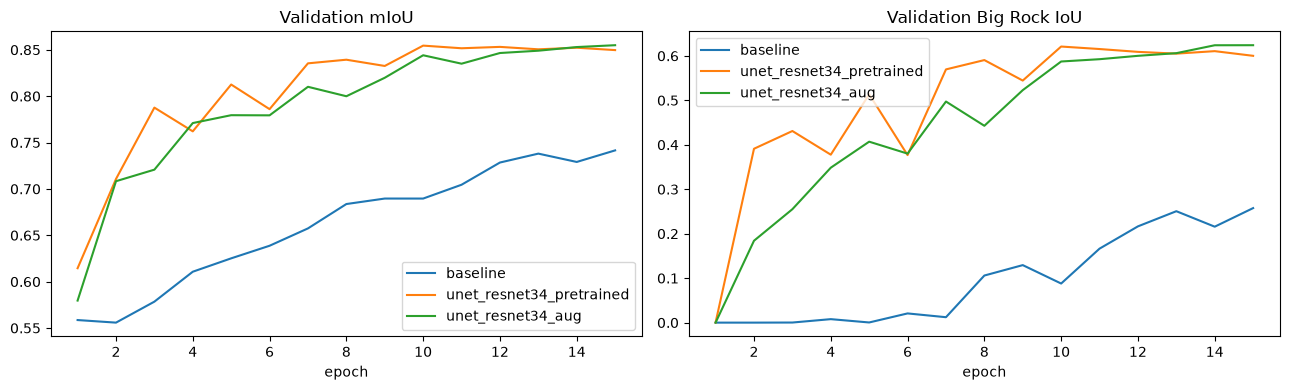

In [8]:
# 4.7 validation curves
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in LOGGED:
    h = pd.DataFrame(json.load(open(RESULTS / name / "history.json")))
    axes[0].plot(h["epoch"], h["val_miou"], label=name)
    axes[1].plot(h["epoch"], h["val_iou_3"], label=name)
axes[0].set_title("Validation mIoU"); axes[1].set_title("Validation Big Rock IoU")
for ax in axes:
    ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.show()